# **UBER BOOKING ANALYSIS 2024**

## *Objective: To explore the NCR Uber bookings dataset, identify patterns in booking status, cancellations, vehicle types, and payment methods, and present the findings through visualization.*

In [2]:
# Importing important libraries:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Importing dataset:

df = pd.read_csv("ncr_ride_bookings.csv")
df.head()

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI


In [4]:
# Data Inspection:

df.shape
df.isnull().sum().sort_values(ascending = False)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Date                               150000 non-null  str    
 1   Time                               150000 non-null  str    
 2   Booking ID                         150000 non-null  str    
 3   Booking Status                     150000 non-null  str    
 4   Customer ID                        150000 non-null  str    
 5   Vehicle Type                       150000 non-null  str    
 6   Pickup Location                    150000 non-null  str    
 7   Drop Location                      150000 non-null  str    
 8   Avg VTAT                           139500 non-null  float64
 9   Avg CTAT                           102000 non-null  float64
 10  Cancelled Rides by Customer        10500 non-null   float64
 11  Reason for cancelling by Customer  10500 non-null 

## DATA CLEANING:

In [5]:
df.groupby("Booking Status")["Booking Value"].count()
df["Booking ID"].duplicated().value_counts()
df.duplicated().sum()

df["Booking ID"] = df["Booking ID"].str.replace('"','',regex=False)
df["Customer ID"] = df["Customer ID"].str.replace('"','',regex=False)

df["DateTime"] = pd.to_datetime(df["Date"] + ' ' + df["Time"])
df = df.drop(columns=["Date","Time"])

flags = ['Cancelled Rides by Customer', 'Cancelled Rides by Driver', 'Incomplete Rides']
df[flags] = df[flags].fillna(0)

df.head()

,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Cancelled Rides by Customer,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method,DateTime
0,CNR5884300,No Driver Found,CID1982111,eBike,Palam Vihar,Jhilmil,NaN,NaN,0.0,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,2024-03-23 12:29:38
1,CNR1326809,Incomplete,CID4604802,Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,0.0,NaN,0.0,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI,2024-11-29 18:01:39
2,CNR8494506,Completed,CID9202816,Auto,Khandsa,Malviya Nagar,13.4,25.8,0.0,NaN,0.0,NaN,0.0,NaN,627.0,13.58,4.9,4.9,Debit Card,2024-08-23 08:56:10
3,CNR8906825,Completed,CID2610914,Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,0.0,NaN,0.0,NaN,0.0,NaN,416.0,34.02,4.6,5.0,UPI,2024-10-21 17:17:25
4,CNR1950162,Completed,CID9933542,Bike,Ghitorni Village,Khan Market,5.3,19.6,0.0,NaN,0.0,NaN,0.0,NaN,737.0,48.21,4.1,4.3,UPI,2024-09-16 22:08:00


## EDA(Exploratory Data Analysis):

In [6]:
# BOOKING STATUS ANALYSIS:

# Percentage of Booking Status:
print("% Of Booking Status:",df["Booking Status"].value_counts(normalize=True) * 100)

print("----------------------------------------------------------")

# Avg Booking value according to Booking Status:
print("Avg Booking Value by Status:",df.groupby("Booking Status")["Booking Value"].mean().sort_values(ascending=False).dropna())

print("----------------------------------------------------------")

# Avg Ride Distance according to Booking Status:
print("Avg Ride Distance by Status:",df.groupby("Booking Status")["Ride Distance"].mean().sort_values(ascending=False).dropna())

print("----------------------------------------------------------")

# Avg Customer rating by Completed rides:
completed = df[df["Booking Status"] == "Completed"]
print("Avg Customer Rating:",completed["Customer Rating"].mean().round(2))

df.to_csv("Uber report data.csv")

% Of Booking Status: Booking Status
Completed                62.0
Cancelled by Driver      18.0
No Driver Found           7.0
Cancelled by Customer     7.0
Incomplete                6.0
Name: proportion, dtype: float64
----------------------------------------------------------
Avg Booking Value by Status: Booking Status
Incomplete    509.512111
Completed     508.178215
Name: Booking Value, dtype: float64
----------------------------------------------------------
Avg Ride Distance by Status: Booking Status
Completed     26.000493
Incomplete    10.547706
Name: Ride Distance, dtype: float64
----------------------------------------------------------
Avg Customer Rating: 4.4


In [7]:
# Cancellation Analysis:

# Top Cancellation reasons:
print("Customer's Reason:",df["Reason for cancelling by Customer"].value_counts().sort_values(ascending=False))

print("----------------------------------------------------------")

print("Driver's Reason:",df["Driver Cancellation Reason"].value_counts().sort_values(ascending=False))

print("----------------------------------------------------------")

# Cancelled rides by Customers:
print("Rides Cancelled by Customers:",df["Cancelled Rides by Customer"].value_counts(normalize=True))

print("----------------------------------------------------------")

# Cancelled rides by Drivers:
print("Rides Cancelled by Drivers:",df["Cancelled Rides by Driver"].value_counts(normalize=True))

Customer's Reason: Reason for cancelling by Customer
Wrong Address                                   2362
Change of plans                                 2353
Driver is not moving towards pickup location    2335
Driver asked to cancel                          2295
AC is not working                               1155
Name: count, dtype: int64
----------------------------------------------------------
Driver's Reason: Driver Cancellation Reason
Customer related issue                 6837
The customer was coughing/sick         6751
Personal & Car related issues          6726
More than permitted people in there    6686
Name: count, dtype: int64
----------------------------------------------------------
Rides Cancelled by Customers: Cancelled Rides by Customer
0.0    0.93
1.0    0.07
Name: proportion, dtype: float64
----------------------------------------------------------
Rides Cancelled by Drivers: Cancelled Rides by Driver
0.0    0.82
1.0    0.18
Name: proportion, dtype: float64


In [8]:
# Payment & Vehicle Analysis:

# Payment Method distribution:
print("Payment Method Distribution:",df["Payment Method"].value_counts(normalize=True) * 100)

print("----------------------------------------------------------")

# Booking value by Payment Methods:
print("Booking value by Payment Method:",df.groupby("Payment Method")["Booking Value"].sum().sort_values(ascending=False))

print("----------------------------------------------------------")

# Most popular Vehicle type:
df["Vehicle Type"].value_counts()
print("% Vehicle Share:",df["Vehicle Type"].value_counts(normalize=True) * 100)

print("----------------------------------------------------------")

# Total Booking value by Vehicle type:
print("Total Booking value by Vehicle type:",df.groupby("Vehicle Type")["Booking Value"].sum().sort_values(ascending=False))

Payment Method Distribution: Payment Method
UPI            45.008824
Cash           24.869608
Uber Wallet    12.035294
Credit Card    10.008824
Debit Card      8.077451
Name: proportion, dtype: float64
----------------------------------------------------------
Booking value by Payment Method: Payment Method
UPI            23345101.0
Cash           12895649.0
Uber Wallet     6200898.0
Credit Card     5224025.0
Debit Card      4180510.0
Name: Booking Value, dtype: float64
----------------------------------------------------------
% Vehicle Share: Vehicle Type
Auto             24.946000
Go Mini          19.870667
Go Sedan         18.094000
Bike             15.011333
Premier Sedan    12.074000
eBike             7.038000
Uber XL           2.966000
Name: proportion, dtype: float64
----------------------------------------------------------
Total Booking value by Vehicle type: Vehicle Type
Auto             12878422.0
Go Mini          10338496.0
Go Sedan          9369719.0
Bike              783

## VISUALIZATION:

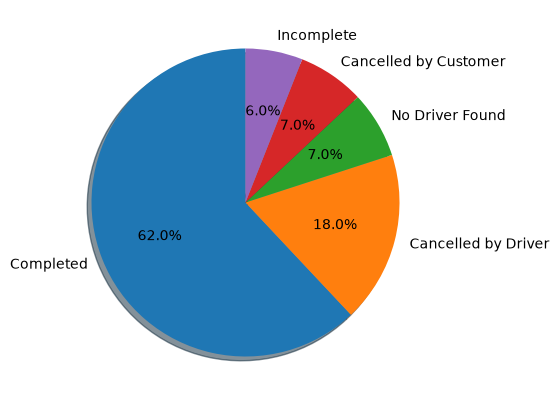

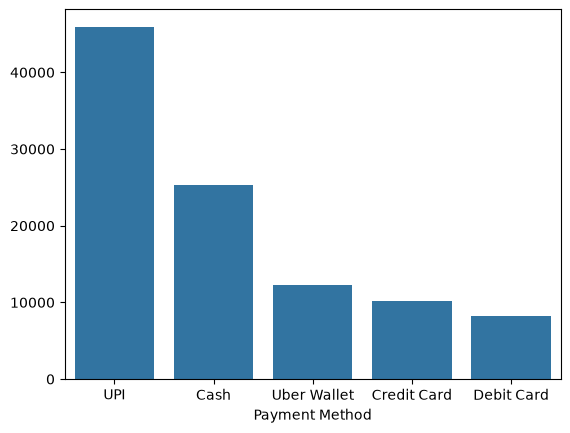

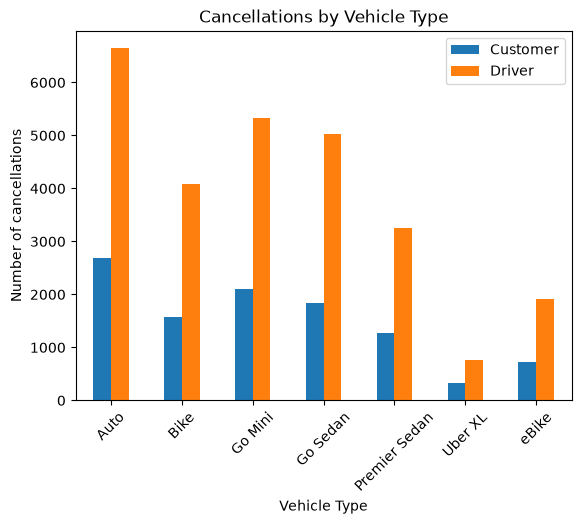

In [9]:
plt.figure(figsize=(7,5))

# Booking Status:
status = df["Booking Status"].value_counts(normalize=True)
plt.pie(status,labels=status.index,autopct='%1.1f%%',shadow=True,startangle=90)
plt.show()

# Payment Method Distribution:
payment = df["Payment Method"].value_counts(ascending=False)
sns.barplot(x=payment.index,y=payment.values)
plt.show()

# Cancellations By Vehicle Type:
cancel = pd.DataFrame({"Customer": (df["Booking Status"] == "Cancelled by Customer").groupby(df["Vehicle Type"]).sum(),
                       "Driver":   (df["Booking Status"] == "Cancelled by Driver").groupby(df["Vehicle Type"]).sum()})

cancel.plot(kind="bar")
plt.title("Cancellations by Vehicle Type")
plt.ylabel("Number of cancellations")
plt.xticks(rotation=45)
plt.show()

## KEY POINTS FROM THE PROJECT:

👉🏻 **The completed ride status is good, alomst 62%. But Uber should focus on rides where the drivers are not available and where the rides are incomplete. They combine and gets almost 13% share which the company can improve if it takes good measures.**

**👉🏻 Completed rides averages 26 km vs 10.55 km for incomplete ones. This could reflect either that short rides are more likely to be abandoned, or that incomplete rides simply stop early (since their recorded distance may be where the ride cut off, not the planned distance).**

**👉🏻 Drivers are cancelling the rides almost double than the customers (7% -> 18%). There is no specific reason for it, the reasons are evenly spread.**

**👉🏻 UPI is the most popular payment method when comes to payment distribution. It accounts for ~₹23.34M booking value, while cash being the second most common method has ₹12.9M booking value. Together they generates 70% booking value.**

**👉🏻 Auto has the largest vehicle share (24.9%) and the highest total booking value (~₹12.9M), but only because it has the most rides, not because it’s priced differently — its average value per ride (₹506.7) is close to every other vehicle type. Go Mini and Go Sedan together make up about 38% of rides.**